# Milestone 1 (UTS) – Prediksi Performance Index Mahasiswa

**Dataset:** `Student_Performance.csv` – [Kaggle (nikhil7280)](https://www.kaggle.com/datasets/nikhil7280/student-performance-multiple-linear-regression)  
**Jenis masalah:** regresi (supervised learning, classical machine learning)

**Cara menjalankan:** letakkan `Student_Performance.csv` di folder yang sama dengan notebook ini, pasang library dengan `pip install -r requirements.txt`, lalu pilih **Run All**. Semua tabel dan grafik juga tersimpan di folder `outputs/`.

Nomor bagian di notebook ini sama dengan nomor bagian yang dirujuk di laporan.

## 0. Konfigurasi
Impor library, konstanta eksperimen (`RANDOM_STATE`, ukuran data uji, jumlah fold), lokasi file, dan pencatatan versi library ke `outputs/versi_lingkungan.txt`.

In [1]:
import platform
import sys
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    PolynomialFeatures,
    StandardScaler,
)
from sklearn.tree import DecisionTreeRegressor

In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_FOLDS = 5

BASE_DIR = Path.cwd()  # folder tempat notebook dibuka
FILE_PATH = BASE_DIR / "Student_Performance.csv"
OUT_DIR = BASE_DIR / "outputs"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

TARGET = "Performance Index"
NUMERIC_FEATURES = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced",
]
CATEGORICAL_FEATURES = ["Extracurricular Activities"]

# Rentang nilai yang wajar menurut deskripsi dataset (dipakai untuk cek validitas)
EXPECTED_RANGE = {
    "Hours Studied": (1, 9),
    "Previous Scores": (40, 99),
    "Sleep Hours": (4, 9),
    "Sample Question Papers Practiced": (0, 9),
    "Performance Index": (10, 100),
}

np.random.seed(RANDOM_STATE)


def judul(teks):
    print("\n" + "=" * 64)
    print(teks)
    print("=" * 64)


def simpan_gambar(nama):
    plt.tight_layout()
    plt.savefig(FIG_DIR / nama, dpi=150)
    print(f"  [grafik] outputs/figures/{nama}")
    plt.show()


# Catat versi library agar hasil dapat direproduksi
with open(OUT_DIR / "versi_lingkungan.txt", "w", encoding="utf-8") as f:
    f.write(f"Dijalankan     : {datetime.now():%Y-%m-%d %H:%M}\n")
    f.write(f"Python         : {sys.version.split()[0]} ({platform.system()})\n")
    f.write(f"pandas         : {pd.__version__}\n")
    f.write(f"numpy          : {np.__version__}\n")
    f.write(f"scikit-learn   : {sklearn.__version__}\n")
    f.write(f"matplotlib     : {matplotlib.__version__}\n")
    f.write(f"random_state   : {RANDOM_STATE}\n")

## 1. Membaca dataset dan data understanding
Memeriksa ukuran, tipe data, missing value, duplikat, rentang nilai, dan baris dengan fitur identik tetapi target berbeda. Ringkasan disimpan di `outputs/ringkasan_kualitas_data.csv` dan `outputs/cek_rentang_nilai.csv`.

In [3]:
if not FILE_PATH.exists():
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Letakkan Student_Performance.csv di folder "
        "yang sama dengan main.ipynb. Sumber: https://www.kaggle.com/datasets/"
        "nikhil7280/student-performance-multiple-linear-regression"
    )

df_raw = pd.read_csv(FILE_PATH)

judul("1. DATA UNDERSTANDING")
print("5 data pertama:")
print(df_raw.head().to_string())
print(f"\nJumlah observasi (baris): {df_raw.shape[0]}")
print(f"Jumlah kolom            : {df_raw.shape[1]} (5 fitur + 1 target)")
print("\nTipe data:")
print(df_raw.dtypes.to_string())

missing = df_raw.isnull().sum()
n_dup = int(df_raw.duplicated().sum())
print("\nMissing value per kolom:")
print(missing.to_string())
print(f"\nBaris duplikat persis (seluruh kolom sama): {n_dup}")

# Cek validitas rentang nilai
print("\nCek rentang nilai:")
range_rows = []
for col, (lo, hi) in EXPECTED_RANGE.items():
    mn, mx = df_raw[col].min(), df_raw[col].max()
    di_luar = int(((df_raw[col] < lo) | (df_raw[col] > hi)).sum())
    range_rows.append({"Kolom": col, "Min": mn, "Max": mx,
                       "Rentang wajar": f"{lo}-{hi}", "Di luar rentang": di_luar})
range_df = pd.DataFrame(range_rows)
print(range_df.to_string(index=False))

print("\nNilai unik fitur kategorikal:")
print(df_raw["Extracurricular Activities"].value_counts().to_string())

# Baris dengan fitur identik tetapi target berbeda (indikasi noise pada target)
fitur_semua = NUMERIC_FEATURES + CATEGORICAL_FEATURES
df_nodup = df_raw.drop_duplicates()
n_konflik = int(df_nodup.duplicated(subset=fitur_semua, keep=False).sum())
print(f"\nBaris (setelah hapus duplikat) yang fiturnya identik dengan baris lain "
      f"tetapi targetnya berbeda: {n_konflik}")

kualitas = pd.DataFrame([
    {"Pemeriksaan": "Jumlah observasi awal", "Hasil": df_raw.shape[0]},
    {"Pemeriksaan": "Jumlah fitur", "Hasil": len(fitur_semua)},
    {"Pemeriksaan": "Total missing value", "Hasil": int(missing.sum())},
    {"Pemeriksaan": "Baris duplikat persis", "Hasil": n_dup},
    {"Pemeriksaan": "Nilai di luar rentang wajar",
     "Hasil": int(range_df["Di luar rentang"].sum())},
    {"Pemeriksaan": "Baris fitur identik, target berbeda", "Hasil": n_konflik},
])
kualitas.to_csv(OUT_DIR / "ringkasan_kualitas_data.csv", index=False)
range_df.to_csv(OUT_DIR / "cek_rentang_nilai.csv", index=False)


1. DATA UNDERSTANDING
5 data pertama:
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  Sample Question Papers Practiced  Performance Index
0              7               99                        Yes            9                                 1               91.0
1              4               82                         No            4                                 2               65.0
2              8               51                        Yes            7                                 2               45.0
3              5               52                        Yes            5                                 2               36.0
4              7               75                         No            8                                 5               66.0

Jumlah observasi (baris): 10000
Jumlah kolom            : 6 (5 fitur + 1 target)

Tipe data:
Hours Studied                         int64
Previous Scores                       int64
Extracurricular A

## 2. Pembersihan data
Duplikat persis dihapus **sebelum** pembagian data agar baris yang sama tidak masuk ke data latih dan data uji sekaligus.

In [4]:
# Duplikat persis dihapus SEBELUM split. Jika tidak, baris yang sama
# bisa masuk ke data latih dan data uji sekaligus sehingga skor uji
# menjadi terlalu optimis (salah satu bentuk data leakage).

judul("2. PEMBERSIHAN DATA")
df = df_raw.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=[TARGET])
print(f"Jumlah data setelah hapus duplikat: {len(df)} "
      f"(berkurang {len(df_raw) - len(df)} baris)")

X = df[fitur_semua]
y = df[TARGET]


2. PEMBERSIHAN DATA
Jumlah data setelah hapus duplikat: 9873 (berkurang 127 baris)


## 3. Pembagian data
Data uji (20%) disisihkan sejak awal dan tidak dipakai untuk EDA, pemilihan fitur, ataupun pemilihan model.

In [5]:
# Data uji disisihkan sejak awal dan tidak dipakai untuk EDA,
# pemilihan fitur, ataupun pemilihan model.

judul("3. PEMBAGIAN DATA")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print(f"Data latih : {len(X_train)} baris ({1 - TEST_SIZE:.0%})")
print(f"Data uji   : {len(X_test)} baris ({TEST_SIZE:.0%})")
print(f"Rata-rata target latih/uji: {y_train.mean():.2f} / {y_test.mean():.2f}")

split_info = pd.DataFrame([
    {"Bagian": "Latih", "Jumlah": len(X_train), "Mean target": y_train.mean(),
     "Std target": y_train.std()},
    {"Bagian": "Uji", "Jumlah": len(X_test), "Mean target": y_test.mean(),
     "Std target": y_test.std()},
])
split_info.to_csv(OUT_DIR / "info_pembagian_data.csv", index=False)


3. PEMBAGIAN DATA
Data latih : 7898 baris (80%)
Data uji   : 1975 baris (20%)
Rata-rata target latih/uji: 55.10 / 55.70


## 4. Exploratory Data Analysis (hanya data latih)
Setiap temuan di laporan bagian C berasal dari sel-sel di bawah ini.

In [6]:
judul("4. EXPLORATORY DATA ANALYSIS (data latih)")
train_df = X_train.copy()
train_df[TARGET] = y_train


4. EXPLORATORY DATA ANALYSIS (data latih)


In [7]:
# 4a. Statistik deskriptif
desc = train_df.describe().T
desc["skewness"] = train_df[NUMERIC_FEATURES + [TARGET]].skew()
print("Statistik deskriptif:")
print(desc.round(2).to_string())
desc.round(4).to_csv(OUT_DIR / "eda_statistik_deskriptif.csv")

Statistik deskriptif:
                                   count   mean    std   min   25%   50%   75%    max  skewness
Hours Studied                     7898.0   4.99   2.59   1.0   3.0   5.0   7.0    9.0     -0.00
Previous Scores                   7898.0  69.33  17.30  40.0  54.0  69.0  85.0   99.0      0.01
Sleep Hours                       7898.0   6.54   1.70   4.0   5.0   7.0   8.0    9.0     -0.05
Sample Question Papers Practiced  7898.0   4.60   2.86   0.0   2.0   5.0   7.0    9.0     -0.04
Performance Index                 7898.0  55.10  19.19  10.0  40.0  55.0  70.0  100.0      0.01


  [grafik] outputs/figures/01_distribusi_target.png


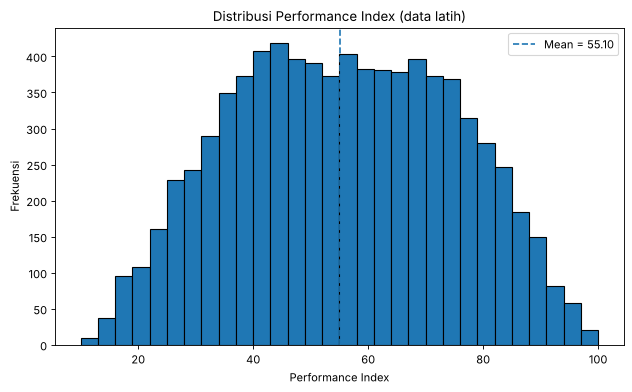

In [8]:
# 4b. Distribusi target
plt.figure(figsize=(8, 5))
plt.hist(y_train, bins=30, edgecolor="black")
plt.axvline(y_train.mean(), linestyle="--", label=f"Mean = {y_train.mean():.2f}")
plt.title("Distribusi Performance Index (data latih)")
plt.xlabel("Performance Index")
plt.ylabel("Frekuensi")
plt.legend()
simpan_gambar("01_distribusi_target.png")

  [grafik] outputs/figures/02_distribusi_fitur.png


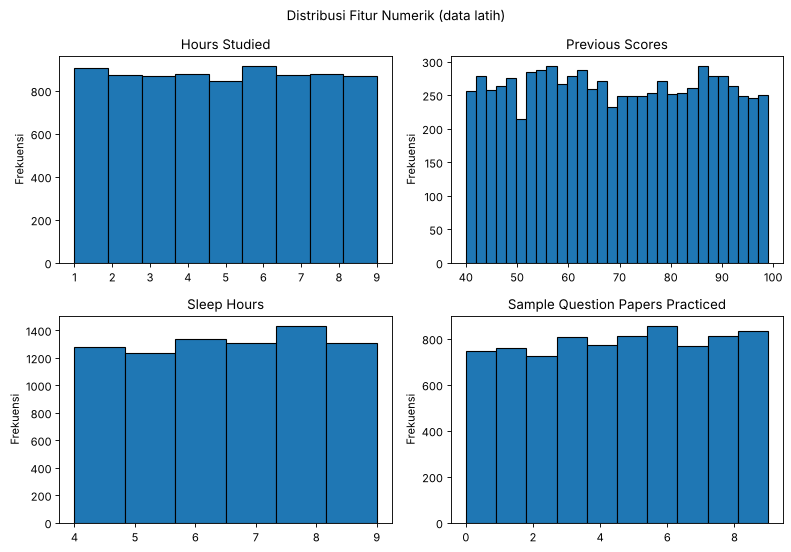

In [9]:
# 4c. Distribusi tiap fitur numerik
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    ax.hist(train_df[col], bins=min(30, train_df[col].nunique()), edgecolor="black")
    ax.set_title(col)
    ax.set_ylabel("Frekuensi")
fig.suptitle("Distribusi Fitur Numerik (data latih)")
simpan_gambar("02_distribusi_fitur.png")


Matriks korelasi Pearson:
                                  Hours Studied  Previous Scores  Sleep Hours  Sample Question Papers Practiced  Extracurricular Activities  Performance Index
Hours Studied                             1.000           -0.009       -0.003                             0.021                       0.004              0.377
Previous Scores                          -0.009            1.000        0.008                            -0.005                       0.008              0.915
Sleep Hours                              -0.003            0.008        1.000                             0.003                      -0.025              0.048
Sample Question Papers Practiced          0.021           -0.005        0.003                             1.000                       0.017              0.032
Extracurricular Activities                0.004            0.008       -0.025                             0.017                       1.000              0.023
Performance Index  

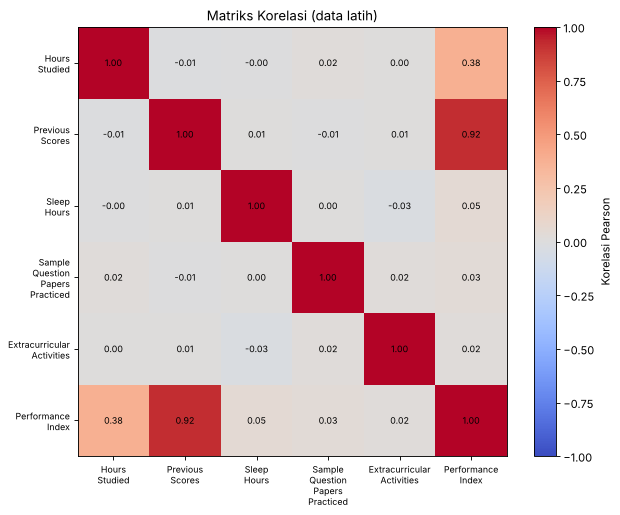

In [10]:
# 4d. Korelasi (Extracurricular diubah ke 0/1 khusus untuk analisis ini)
corr_df = train_df.copy()
corr_df["Extracurricular Activities"] = (
    corr_df["Extracurricular Activities"] == "Yes").astype(int)
correlation = corr_df.corr()
print("\nMatriks korelasi Pearson:")
print(correlation.round(3).to_string())
correlation.round(4).to_csv(OUT_DIR / "eda_matriks_korelasi.csv")

plt.figure(figsize=(8, 6.5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Korelasi Pearson")
labels = [c.replace(" ", "\n") for c in correlation.columns]
plt.xticks(range(len(labels)), labels, fontsize=8)
plt.yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)
plt.title("Matriks Korelasi (data latih)")
simpan_gambar("03_matriks_korelasi.png")


Rata-rata target pada nilai fitur terendah dan tertinggi:
                           Fitur  Nilai terendah  Mean target (nilai terendah)  Nilai tertinggi  Mean target (nilai tertinggi)  Min mean target  Max mean target
                   Hours Studied               1                         43.60                9                          65.44            43.60            65.44
                 Previous Scores              40                         23.92               99                          85.43            23.92            85.43
                     Sleep Hours               4                         53.83                9                          56.52            53.83            56.52
Sample Question Papers Practiced               0                         53.40                9                          56.47            53.40            56.47
  [grafik] outputs/figures/04_rata_target_per_fitur.png


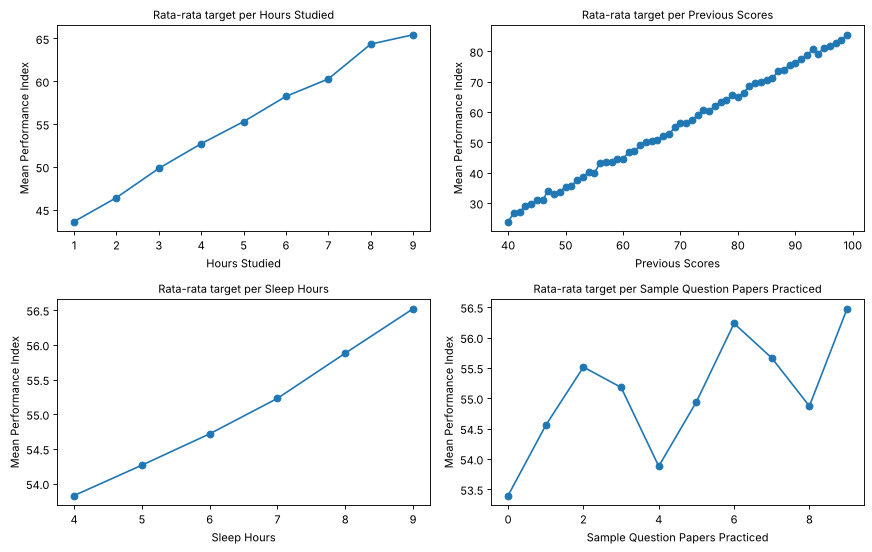

In [11]:
# 4e. Rata-rata target per nilai fitur (cek pola linear)
rata_rows = []
for col in NUMERIC_FEATURES:
    rata = train_df.groupby(col)[TARGET].mean()
    rata_rows.append({"Fitur": col, "Nilai terendah": rata.index.min(),
                      "Mean target (nilai terendah)": rata.iloc[0],
                      "Nilai tertinggi": rata.index.max(),
                      "Mean target (nilai tertinggi)": rata.iloc[-1],
                      "Min mean target": rata.min(), "Max mean target": rata.max()})
rata_df = pd.DataFrame(rata_rows)
print("\nRata-rata target pada nilai fitur terendah dan tertinggi:")
print(rata_df.round(2).to_string(index=False))
rata_df.round(4).to_csv(OUT_DIR / "eda_rata_target_per_fitur.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    rata = train_df.groupby(col)[TARGET].mean()
    ax.plot(rata.index, rata.values, marker="o")
    ax.set_title(f"Rata-rata target per {col}", fontsize=10)
    ax.set_xlabel(col)
    ax.set_ylabel("Mean Performance Index")
simpan_gambar("04_rata_target_per_fitur.png")

  [grafik] outputs/figures/05_scatter_previous_scores.png


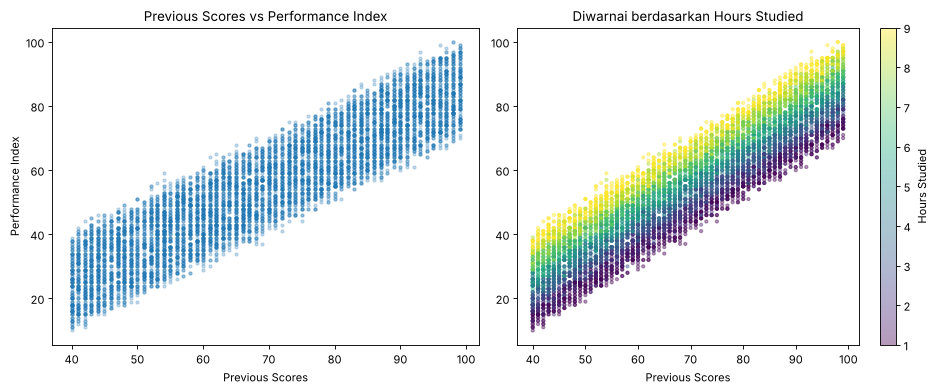

In [12]:
# 4f. Scatter dua fitur dengan korelasi tertinggi
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(train_df["Previous Scores"], train_df[TARGET], alpha=0.25, s=8)
axes[0].set_xlabel("Previous Scores")
axes[0].set_ylabel(TARGET)
axes[0].set_title("Previous Scores vs Performance Index")
sc = axes[1].scatter(train_df["Previous Scores"], train_df[TARGET],
                     c=train_df["Hours Studied"], cmap="viridis", alpha=0.4, s=8)
fig.colorbar(sc, ax=axes[1], label="Hours Studied")
axes[1].set_xlabel("Previous Scores")
axes[1].set_title("Diwarnai berdasarkan Hours Studied")
simpan_gambar("05_scatter_previous_scores.png")


Performance Index per kelompok ekstrakurikuler:
                            count   mean  median    std
Extracurricular Activities                             
No                           3973  54.66    55.0  19.14
Yes                          3925  55.54    55.0  19.22
  [grafik] outputs/figures/06_boxplot_ekstrakurikuler.png


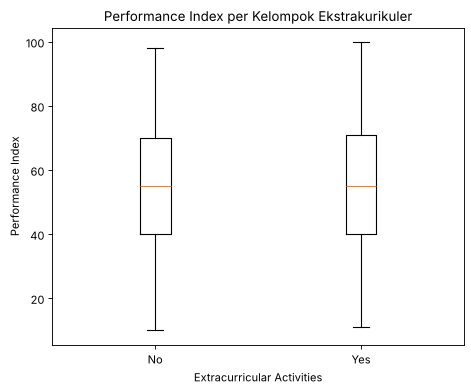

In [13]:
# 4g. Perbandingan kelompok ekstrakurikuler
grup = train_df.groupby("Extracurricular Activities")[TARGET].agg(
    ["count", "mean", "median", "std"])
print("\nPerformance Index per kelompok ekstrakurikuler:")
print(grup.round(2).to_string())
grup.round(4).to_csv(OUT_DIR / "eda_ekstrakurikuler.csv")

plt.figure(figsize=(6, 5))
plt.boxplot([train_df.loc[train_df["Extracurricular Activities"] == k, TARGET]
             for k in ["No", "Yes"]])
plt.xticks([1, 2], ["No", "Yes"])
plt.xlabel("Extracurricular Activities")
plt.ylabel(TARGET)
plt.title("Performance Index per Kelompok Ekstrakurikuler")
simpan_gambar("06_boxplot_ekstrakurikuler.png")

In [14]:
# 4h. Outlier (metode IQR) pada fitur numerik dan target
print("\nJumlah outlier (aturan 1.5 x IQR):")
outlier_rows = []
for col in NUMERIC_FEATURES + [TARGET]:
    q1, q3 = train_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((train_df[col] < q1 - 1.5 * iqr) |
                 (train_df[col] > q3 + 1.5 * iqr)).sum())
    outlier_rows.append({"Kolom": col, "Outlier IQR": n_out})
    print(f"  {col:35s}: {n_out}")
pd.DataFrame(outlier_rows).to_csv(OUT_DIR / "eda_outlier.csv", index=False)


Jumlah outlier (aturan 1.5 x IQR):
  Hours Studied                      : 0
  Previous Scores                    : 0
  Sleep Hours                        : 0
  Sample Question Papers Practiced   : 0
  Performance Index                  : 0


In [15]:
# 4i. Perkiraan batas bawah error (noise pada target)
# Untuk kelompok baris latih dengan fitur identik, perbedaan target tidak
# mungkin dijelaskan oleh fitur apa pun. Simpangan bakunya menjadi gambaran
# kasar error minimum yang bisa dicapai model.
grp = train_df.groupby(fitur_semua)[TARGET]
ukuran = grp.transform("size")
dalam_grup = train_df[ukuran > 1]
if len(dalam_grup) > 0:
    sisa = dalam_grup[TARGET] - dalam_grup.groupby(fitur_semua)[TARGET].transform("mean")
    n_grup = dalam_grup.groupby(fitur_semua).ngroups
    noise_std = float(np.sqrt((sisa ** 2).sum() / (len(dalam_grup) - n_grup)))
else:
    n_grup, noise_std = 0, float("nan")
print(f"\nKelompok fitur identik di data latih: {n_grup} kelompok, "
      f"{len(dalam_grup)} baris")
print(f"Perkiraan simpangan baku noise target: {noise_std:.4f}")
pd.DataFrame([{"Kelompok fitur identik": n_grup,
               "Baris terlibat": len(dalam_grup),
               "Perkiraan std noise": noise_std}]).to_csv(
    OUT_DIR / "eda_perkiraan_noise.csv", index=False)


Kelompok fitur identik di data latih: 413 kelompok, 837 baris
Perkiraan simpangan baku noise target: 2.1393


## 5. Preprocessing
Imputer, scaler, dan encoder berada di dalam `Pipeline`, sehingga parameternya hanya dipelajari dari data latih pada setiap fold.

In [16]:
# Semua langkah dimasukkan ke dalam Pipeline sehingga parameter
# (median, skala, kategori) dipelajari hanya dari data latih pada
# setiap fold, lalu diterapkan ke data validasi/uji.

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),  # jaga-jaga untuk data baru
    ("scaler", StandardScaler()),                   # perlu untuk Ridge dan KNN
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="ignore")),
])


def buat_preprocessor():
    return ColumnTransformer(transformers=[
        ("num", numeric_transformer, NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
    ])

## 6. Feature engineering awal
FE-1: interaksi Hours Studied × Previous Scores. FE-2: rasio latihan soal per jam belajar. FE-3: polinomial derajat 2.

In [17]:
# FE-1: interaksi Hours Studied x Previous Scores.
#       Alasan: menguji apakah efek jam belajar bergantung pada nilai sebelumnya.
# FE-2: rasio latihan soal terhadap jam belajar.
#       Alasan: menguji apakah "intensitas latihan" memberi informasi tambahan.
# FE-3: polinomial derajat 2 untuk semua fitur (kuadrat + semua interaksi).
# Transformasi FE-1 dan FE-2 bersifat baris-per-baris (tidak mempelajari
# statistik dari data), sehingga tidak menimbulkan leakage.

FE_NUMERIC = NUMERIC_FEATURES + ["Hours_x_PrevScores", "Papers_per_Hour"]


def tambah_fitur(data):
    data = data.copy()
    data["Hours_x_PrevScores"] = data["Hours Studied"] * data["Previous Scores"]
    data["Papers_per_Hour"] = (data["Sample Question Papers Practiced"]
                               / data["Hours Studied"])
    return data


def buat_preprocessor_fe():
    return ColumnTransformer(transformers=[
        ("num", Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())]), FE_NUMERIC),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
    ])

## 7. Baseline dan model kandidat
Dua baseline (E01–E02), enam model kandidat (E03–E08), dan tiga eksperimen feature engineering (E09–E11).

In [18]:
def pipe(model, fitur="dasar"):
    if fitur == "dasar":
        return Pipeline([("prep", buat_preprocessor()), ("model", model)])
    if fitur == "fe":
        return Pipeline([("fe", FunctionTransformer(tambah_fitur)),
                         ("prep", buat_preprocessor_fe()), ("model", model)])
    if fitur == "poly2":
        return Pipeline([("prep", buat_preprocessor()),
                         ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                         ("model", model)])
    if fitur == "satu_fitur":
        return Pipeline([("pilih", ColumnTransformer(
            [("ps", "passthrough", ["Previous Scores"])])), ("model", model)])
    raise ValueError(fitur)


eksperimen = [
    # id, nama, jenis, set fitur, pipeline, parameter penting
    ("E01", "Dummy (mean)", "Baseline", "dasar",
     pipe(DummyRegressor(strategy="mean")), "strategy=mean"),
    ("E02", "Linear Regression (Previous Scores saja)", "Baseline", "satu_fitur",
     pipe(LinearRegression(), "satu_fitur"), "1 fitur"),
    ("E03", "Linear Regression", "Kandidat", "dasar",
     pipe(LinearRegression()), "default"),
    ("E04", "Ridge Regression", "Kandidat", "dasar",
     pipe(Ridge(alpha=1.0)), "alpha=1.0"),
    ("E05", "KNN Regressor", "Kandidat", "dasar",
     pipe(KNeighborsRegressor(n_neighbors=10)), "k=10"),
    ("E06", "Decision Tree", "Kandidat", "dasar",
     pipe(DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE)),
     "max_depth=8"),
    ("E07", "Random Forest", "Kandidat", "dasar",
     pipe(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE,
                                n_jobs=-1)), "n_estimators=200"),
    ("E08", "Gradient Boosting", "Kandidat", "dasar",
     pipe(GradientBoostingRegressor(random_state=RANDOM_STATE)),
     "n_estimators=100, lr=0.1"),
    ("E09", "Linear Regression + FE (interaksi & rasio)", "Feature eng.", "fe",
     pipe(LinearRegression(), "fe"), "FE-1 + FE-2"),
    ("E10", "Linear Regression + Polinomial derajat 2", "Feature eng.", "poly2",
     pipe(LinearRegression(), "poly2"), "degree=2"),
    ("E11", "Random Forest + FE (interaksi & rasio)", "Feature eng.", "fe",
     pipe(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE,
                                n_jobs=-1), "fe"), "n_estimators=200, FE-1 + FE-2"),
]

## 8. Validasi silang 5-fold pada data latih
Dasar pemilihan model. Hasil: `outputs/hasil_validasi_silang.csv`.

In [19]:
judul(f"8. VALIDASI SILANG {N_FOLDS}-FOLD (data latih)")
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

hasil_cv = []
for eid, nama, jenis, fitur, model, param in eksperimen:
    skor = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                          return_train_score=True, n_jobs=1)
    baris = {
        "ID": eid, "Model": nama, "Jenis": jenis, "Set fitur": fitur,
        "Parameter": param,
        "Validasi": f"{N_FOLDS}-fold KFold (shuffle, rs={RANDOM_STATE})",
        "CV MAE": -skor["test_MAE"].mean(), "CV MAE std": skor["test_MAE"].std(),
        "CV RMSE": -skor["test_RMSE"].mean(), "CV RMSE std": skor["test_RMSE"].std(),
        "CV R2": skor["test_R2"].mean(), "CV R2 std": skor["test_R2"].std(),
        "Train RMSE": -skor["train_RMSE"].mean(),
    }
    hasil_cv.append(baris)
    print(f"{eid} {nama:45s} RMSE={baris['CV RMSE']:.4f} "
          f"(±{baris['CV RMSE std']:.4f})  R2={baris['CV R2']:.4f}")

cv_df = pd.DataFrame(hasil_cv)
cv_df["Selisih RMSE (CV - Train)"] = cv_df["CV RMSE"] - cv_df["Train RMSE"]
cv_df.round(4).to_csv(OUT_DIR / "hasil_validasi_silang.csv", index=False)


8. VALIDASI SILANG 5-FOLD (data latih)
E01 Dummy (mean)                                  RMSE=19.1881 (±0.1007)  R2=-0.0011
E02 Linear Regression (Previous Scores saja)      RMSE=7.7262 (±0.0440)  R2=0.8377
E03 Linear Regression                             RMSE=2.0375 (±0.0296)  R2=0.9887
E04 Ridge Regression                              RMSE=2.0375 (±0.0296)  R2=0.9887
E05 KNN Regressor                                 RMSE=3.0066 (±0.0533)  R2=0.9754
E06 Decision Tree                                 RMSE=2.5434 (±0.0501)  R2=0.9824
E07 Random Forest                                 RMSE=2.3486 (±0.0321)  R2=0.9850
E08 Gradient Boosting                             RMSE=2.1247 (±0.0265)  R2=0.9877
E09 Linear Regression + FE (interaksi & rasio)    RMSE=2.0387 (±0.0298)  R2=0.9887
E10 Linear Regression + Polinomial derajat 2      RMSE=2.0404 (±0.0307)  R2=0.9887
E11 Random Forest + FE (interaksi & rasio)        RMSE=2.3264 (±0.0372)  R2=0.9853


## 9. Evaluasi akhir pada data uji
Setiap model dilatih ulang pada seluruh data latih lalu dievaluasi satu kali pada data uji. Tabel hasil: `outputs/tabel_hasil_eksperimen.csv`.


9. EVALUASI PADA DATA UJI
 ID                                      Model  CV RMSE   CV R2  Test MAE  Test RMSE  Test R2
E01                               Dummy (mean)  19.1881 -0.0011   16.2526    19.3010  -0.0010
E02   Linear Regression (Previous Scores saja)   7.7262  0.8377    6.7087     7.8173   0.8358
E03                          Linear Regression   2.0375  0.9887    1.6470     2.0751   0.9884
E04                           Ridge Regression   2.0375  0.9887    1.6470     2.0751   0.9884
E05                              KNN Regressor   3.0066  0.9754    2.3708     2.9457   0.9767
E06                              Decision Tree   2.5434  0.9824    2.0415     2.5733   0.9822
E07                              Random Forest   2.3486  0.9850    1.8938     2.3665   0.9850
E08                          Gradient Boosting   2.1247  0.9877    1.6958     2.1391   0.9877
E09 Linear Regression + FE (interaksi & rasio)   2.0387  0.9887    1.6466     2.0746   0.9884
E10   Linear Regression + Polinom

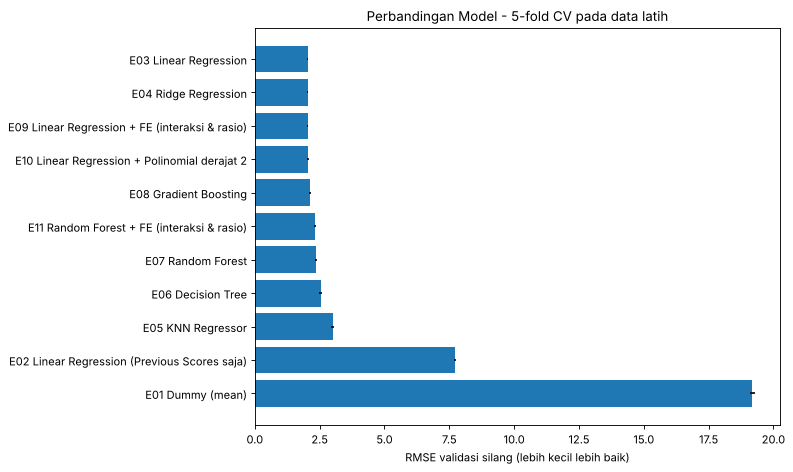

In [20]:
# Setiap model dilatih ulang pada seluruh data latih, lalu dievaluasi
# SATU KALI pada data uji. Pemilihan model tetap didasarkan pada skor CV.

judul("9. EVALUASI PADA DATA UJI")
hasil_test = []
fitted = {}
for eid, nama, jenis, fitur, model, param in eksperimen:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[eid] = (model, pred)
    hasil_test.append({
        "ID": eid, "Model": nama,
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
        "Test R2": r2_score(y_test, pred),
    })
test_df = pd.DataFrame(hasil_test)

tabel = cv_df.merge(test_df, on=["ID", "Model"])
kolom_tabel = ["ID", "Model", "Jenis", "Validasi", "CV MAE", "CV RMSE",
               "CV RMSE std", "CV R2", "Train RMSE", "Test MAE", "Test RMSE",
               "Test R2"]
tabel[kolom_tabel].round(4).to_csv(OUT_DIR / "tabel_hasil_eksperimen.csv",
                                   index=False)
print(tabel[["ID", "Model", "CV RMSE", "CV R2", "Test MAE", "Test RMSE",
             "Test R2"]].round(4).to_string(index=False))

# Model terbaik dipilih dari CV RMSE terkecil (bukan dari skor uji)
best_row = cv_df.sort_values("CV RMSE").iloc[0]
best_id = best_row["ID"]
best_model, best_pred = fitted[best_id]
best_test = test_df.set_index("ID").loc[best_id]
print(f"\nModel terbaik (CV RMSE terkecil): {best_id} - {best_row['Model']}")
print(f"  CV RMSE  : {best_row['CV RMSE']:.4f}")
print(f"  Test RMSE: {best_test['Test RMSE']:.4f} | Test R2: {best_test['Test R2']:.4f}")

# Grafik perbandingan CV RMSE
urut = cv_df.sort_values("CV RMSE", ascending=False)
plt.figure(figsize=(10, 6))
plt.barh(urut["ID"] + " " + urut["Model"], urut["CV RMSE"],
         xerr=urut["CV RMSE std"])
plt.xlabel("RMSE validasi silang (lebih kecil lebih baik)")
plt.title(f"Perbandingan Model - {N_FOLDS}-fold CV pada data latih")
simpan_gambar("07_perbandingan_cv_rmse.png")

## 10. Analisis residual model terbaik


10. ANALISIS RESIDUAL
Mean residual          : 0.0609
Std residual           : 2.0742
|residual| <= 2 poin   : 67.14%
|residual| maksimum    : 7.6098
  [grafik] outputs/figures/08_residual_model_terbaik.png


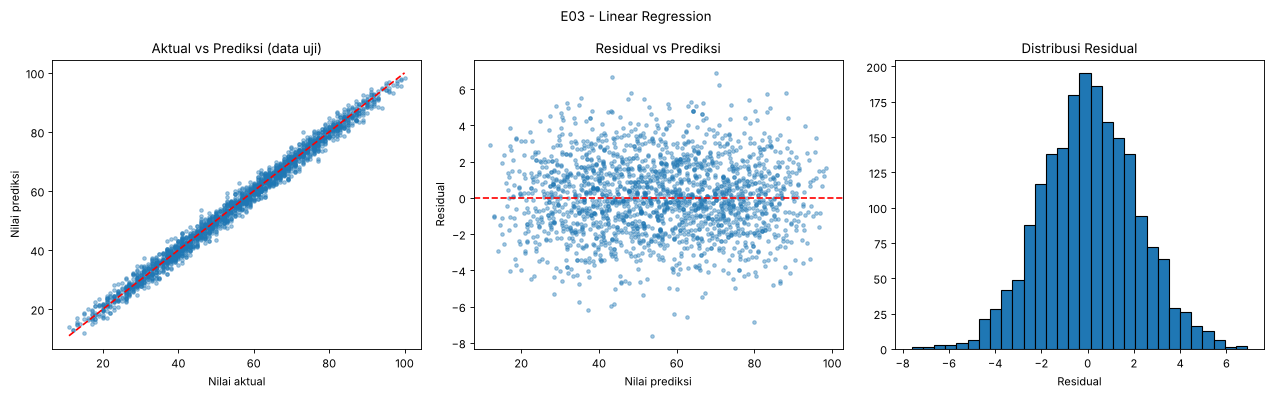

In [21]:
judul("10. ANALISIS RESIDUAL")
residual = y_test.values - best_pred
print(f"Mean residual          : {residual.mean():.4f}")
print(f"Std residual           : {residual.std():.4f}")
print(f"|residual| <= 2 poin   : {(np.abs(residual) <= 2).mean():.2%}")
print(f"|residual| maksimum    : {np.abs(residual).max():.4f}")
pd.DataFrame([{
    "Model": best_row["Model"], "Mean residual": residual.mean(),
    "Std residual": residual.std(),
    "Proporsi |residual| <= 2": (np.abs(residual) <= 2).mean(),
    "|residual| maks": np.abs(residual).max(),
}]).round(4).to_csv(OUT_DIR / "ringkasan_residual.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
lo = min(y_test.min(), best_pred.min())
hi = max(y_test.max(), best_pred.max())
axes[0].scatter(y_test, best_pred, alpha=0.4, s=10)
axes[0].plot([lo, hi], [lo, hi], "--", color="red")
axes[0].set_xlabel("Nilai aktual")
axes[0].set_ylabel("Nilai prediksi")
axes[0].set_title("Aktual vs Prediksi (data uji)")
axes[1].scatter(best_pred, residual, alpha=0.4, s=10)
axes[1].axhline(0, linestyle="--", color="red")
axes[1].set_xlabel("Nilai prediksi")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residual vs Prediksi")
axes[2].hist(residual, bins=30, edgecolor="black")
axes[2].set_xlabel("Residual")
axes[2].set_title("Distribusi Residual")
fig.suptitle(f"{best_id} - {best_row['Model']}")
simpan_gambar("08_residual_model_terbaik.png")

## 11. Interpretasi fitur
Koefisien Linear Regression (fitur distandarkan) dan permutation importance pada data uji.

In [22]:
judul("11. INTERPRETASI FITUR")


11. INTERPRETASI FITUR


In [23]:
# 11a. Koefisien Linear Regression (fitur distandarkan -> dapat dibandingkan)
lr_model = fitted["E03"][0]
coef_df = pd.DataFrame({
    "Fitur": lr_model.named_steps["prep"].get_feature_names_out(),
    "Koefisien (per 1 std fitur)": lr_model.named_steps["model"].coef_,
}).sort_values("Koefisien (per 1 std fitur)", key=np.abs, ascending=False)
print("Koefisien Linear Regression (E03), fitur numerik sudah distandarkan:")
print(coef_df.round(4).to_string(index=False))
coef_df.round(4).to_csv(OUT_DIR / "koefisien_linear_regression.csv", index=False)

Koefisien Linear Regression (E03), fitur numerik sudah distandarkan:
                                Fitur  Koefisien (per 1 std fitur)
                 num__Previous Scores                      17.6199
                   num__Hours Studied                       7.3733
                     num__Sleep Hours                       0.8021
  cat__Extracurricular Activities_Yes                       0.5738
num__Sample Question Papers Practiced                       0.5401



Permutation importance (E03, data uji):
                           Fitur  Kenaikan RMSE (mean)  Kenaikan RMSE (std)
                 Previous Scores               23.0628               0.1700
                   Hours Studied                8.5965               0.0690
                     Sleep Hours                0.3048               0.0207
Sample Question Papers Practiced                0.1558               0.0088
      Extracurricular Activities                0.0551               0.0051
  [grafik] outputs/figures/09_permutation_importance.png


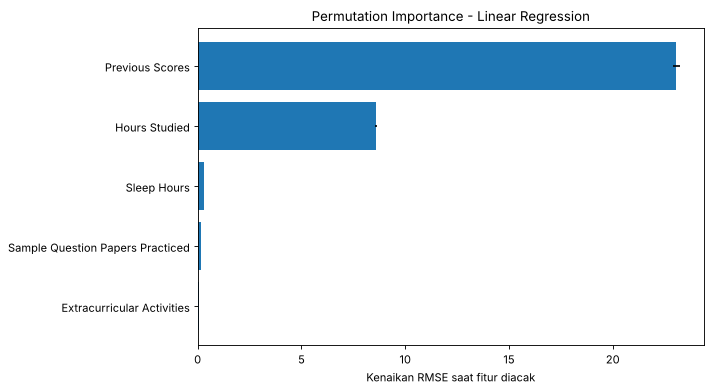

In [24]:
# 11b. Permutation importance pada data uji (berlaku untuk model apa pun)
perm = permutation_importance(best_model, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error")
perm_df = pd.DataFrame({
    "Fitur": X_test.columns,
    "Kenaikan RMSE (mean)": perm.importances_mean,
    "Kenaikan RMSE (std)": perm.importances_std,
}).sort_values("Kenaikan RMSE (mean)", ascending=False)
print(f"\nPermutation importance ({best_id}, data uji):")
print(perm_df.round(4).to_string(index=False))
perm_df.round(4).to_csv(OUT_DIR / "permutation_importance.csv", index=False)

urut_p = perm_df.sort_values("Kenaikan RMSE (mean)")
plt.figure(figsize=(9, 5))
plt.barh(urut_p["Fitur"], urut_p["Kenaikan RMSE (mean)"],
         xerr=urut_p["Kenaikan RMSE (std)"])
plt.xlabel("Kenaikan RMSE saat fitur diacak")
plt.title(f"Permutation Importance - {best_row['Model']}")
simpan_gambar("09_permutation_importance.png")

## 12. Log eksperimen
Catatan semua eksperimen disimpan di `outputs/log_eksperimen.csv`.

In [25]:
log = tabel[["ID", "Model", "Jenis", "Set fitur", "Parameter", "Validasi",
             "CV RMSE", "CV R2", "Test RMSE", "Test R2"]].copy()
log.insert(0, "Waktu", datetime.now().strftime("%Y-%m-%d %H:%M"))
log["random_state"] = RANDOM_STATE
log["Data latih/uji"] = f"{len(X_train)}/{len(X_test)}"
log.round(4).to_csv(OUT_DIR / "log_eksperimen.csv", index=False)

## 13. Contoh prediksi data baru

In [26]:
judul("13. CONTOH PREDIKSI DATA BARU")
# Nilai contoh berada di dalam rentang data latih.
new_student = pd.DataFrame([{
    "Hours Studied": 7,
    "Previous Scores": 80,
    "Extracurricular Activities": "Yes",
    "Sleep Hours": 7,
    "Sample Question Papers Practiced": 5,
}])[fitur_semua]
print(new_student.to_string(index=False))
print(f"Prediksi Performance Index ({best_row['Model']}): "
      f"{best_model.predict(new_student)[0]:.2f}")

print("\nSelesai. Semua hasil tersimpan di folder outputs/.")


13. CONTOH PREDIKSI DATA BARU
 Hours Studied  Previous Scores  Sleep Hours  Sample Question Papers Practiced Extracurricular Activities
             7               80            7                                 5                        Yes
Prediksi Performance Index (Linear Regression): 72.27

Selesai. Semua hasil tersimpan di folder outputs/.
